# 🧹 Limpieza de datos

Notebook interactivo para explorar, limpiar y exportar los datos.
Al final, los datos limpios se guardan en `data/processed/datos_limpios.csv`
para ser consumidos por el dashboard.

In [19]:
# Ajuste de ruta para importar desde src/
import sys
from difflib import SequenceMatcher
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))

import re 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RAW_CSV, PROCESSED_CSV, RAW_DIR, PROCESSED_DIR

# Configuración de visualización
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print(f"CSV crudo: {RAW_CSV}")
print(f"CSV limpio: {PROCESSED_CSV}")

CSV crudo: C:\Users\Angel\Desktop\Sistemas Inteligentes\LimpiezaData\data\raw\datos_raw.csv
CSV limpio: C:\Users\Angel\Desktop\Sistemas Inteligentes\LimpiezaData\data\processed\datos_limpios.csv


## 1. Cargar datos crudos

In [20]:
df = pd.read_csv(RAW_CSV)
print(f"Shape original: {df.shape}")
df.head()

Shape original: (20, 21)


,Marca temporal,Dirección de correo electrónico,¿Deseas participar en el estudio?,¿A qué área de conocimiento pertenece tu carrera?,¿Cuál es tu carrera?,¿En qué semestre te encuentras actualmente?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
0,12/10/2026 16:26:08,321184074@pcpuma.acatlan.unam.mx,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,30/10/2026 18:40:27,321188065@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las I...,Matemáticas Aplicadas y Computación,7.0,Si,14.0,Es un sentimiento dirigido hacia otra persona ...,Honestidad y confianza,No lastimar física o emocionalmente a la otra ...,"El apoyo, porque me hace sentir especial e imp...",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de con...",Frases para controlar o atacar emocionalmente ...,+/- 2 años,Querer estar cerca de la otra persona.\nDarle ...,Tratarme cómo una persona normal y ser paciente.,Hablar de lo que pasó cuando el enojo haya pas...,Un viaje a otro país.,Cómo si fuera la primera vez
2,30/10/2026 18:55:47,424059594@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las I...,Matemáticas Aplicadas y Computación,7.0,No,12.0,Que una persona te genere muchas emociones y n...,Honestidad y lealtad,Ser leal,Cariño ya que me hace sentir querido por esa p...,"Leal, respetuosa, cariñosa y con buen sentido ...",Infidelidad y Falta de Respeto,Que me hable mucho de sus relaciones anteriore...,+/- 4 años,"Tiempo, detalles, palabras y sobre todo estar ...",Escucharme hablar del mismo tema infinidad de ...,Hablando y teniendo una buena comunicación,Un día en un parque de diversiones y después u...,La canción Mi Riqueza
3,30/10/2026 23:58:24,423085822@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las I...,MAC,7.0,Si,15.0,Escuche Amar y querer de José José para más de...,"Comunicación, la capacidad de ser vulnerable.","No pasarse de ""chistoso"".","Comunicación, porque así puedo estar en sus za...",De baja estatura.,-Infidelidad. \n-Manipulación.\n-Falta de empa...,"El que violente física, emocionalmente de mi. ...",+/- 3 años,"Tener retroalimentación, pasar un rato juntos,...","Que sean materialistas, detallistas y escuchen.","Hablar juntos, ya sea comiendo, corriendo, jug...",Simplemente estar con esa persona lo hace idea...,"Something About You de Eyedress y Dent May, re..."
4,31/10/2026 13:10:25,424000455@pcpuma.acatlan.unam.mx,Sí,Área 1: Ciencias Físico-Matemáticas y de las I...,MAC,7.0,No,12.0,Que te atraiga la persona y que la aceptes com...,Honestidad,Que respete mis límites,Empatía,Alto,Que sea mentiroso que sea indeciso,Controlador que sea grosero,2 años más que yo,Detalles tiempo de calidad,Sorprenderme en mi cumpleaños,Hablarlo,Una cita romántica,Love Rosie


## 2. Exploración inicial

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 21 columns):
 #   Column                                                                                Non-Null Count  Dtype  
---  ------                                                                                --------------  -----  
 0   Marca temporal                                                                        20 non-null     str    
 1   Dirección de correo electrónico                                                       20 non-null     str    
 2   ¿Deseas participar en el estudio?                                                     20 non-null     str    
 3   ¿A qué área de conocimiento pertenece tu carrera?                                     19 non-null     str    
 4   ¿Cuál es tu carrera?                                                                  19 non-null     str    
 5   ¿En qué semestre te encuentras actualmente?                                           19 non-null 

In [22]:
# Seleccionamos la columna de quién desea participar y la de tiempo
col_participar = df.columns[2]
col_tiempo = df.columns[0]

# Mapear "Sí" → 1, "No" → 0
df[col_participar] = df[col_participar].map({"Sí": 1, "No": 0})
df = df[df[col_participar] == 1].copy()

# Eliminar columnas innecesarias
df = df.drop(columns=[col_participar, col_tiempo])

In [23]:
# Extraer números de cuenta
df = df.rename(columns={df.columns[0]: "No. Cuenta"})
col_cuenta = df.columns[0]
df[col_cuenta] = df[col_cuenta].astype(str).str.extract(r'(\d{9})')

In [24]:
display(df.describe(include='all'))

,No. Cuenta,¿A qué área de conocimiento pertenece tu carrera?,¿Cuál es tu carrera?,¿En qué semestre te encuentras actualmente?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
count,19,19,19,19.0,19,19.000000,19,19,19,19,19,19,19,19,19,19,19,19,19
unique,19,1,11,NaN,4,NaN,19,19,19,19,19,19,19,16,19,19,18,19,19
top,321188065,Área 1: Ciencias Físico-Matemáticas y de las I...,Matemáticas Aplicadas y Computación,NaN,No,NaN,Es un sentimiento dirigido hacia otra persona ...,Honestidad y confianza,No lastimar física o emocionalmente a la otra ...,"El apoyo, porque me hace sentir especial e imp...",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de con...",Frases para controlar o atacar emocionalmente ...,3 años de diferencia,Querer estar cerca de la otra persona.\nDarle ...,Tratarme cómo una persona normal y ser paciente.,Hablarlo,Un viaje a otro país.,Cómo si fuera la primera vez
freq,1,19,4,NaN,9,NaN,1,1,1,1,1,1,1,2,1,1,2,1,1
mean,NaN,NaN,NaN,7.0,NaN,12.684211,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,0.0,NaN,6.280947,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,7.0,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,7.0,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,7.0,NaN,14.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,7.0,NaN,16.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
# Eliminando la columna del área de conocimiento (todos son de la 1)
# Eliminando la columna del semestre, todos son de 7mo
df = df.drop(columns=[df.columns[1], df.columns[3]])

In [26]:
# Exploración de columnas
display(df.head(10))
df.dtypes

,No. Cuenta,¿Cuál es tu carrera?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,Matemáticas Aplicadas y Computación,Si,14.0,Es un sentimiento dirigido hacia otra persona ...,Honestidad y confianza,No lastimar física o emocionalmente a la otra ...,"El apoyo, porque me hace sentir especial e imp...",No me fijo físicamente en alguien.,"Infidelidad, mentiras, engaños y tratar de con...",Frases para controlar o atacar emocionalmente ...,+/- 2 años,Querer estar cerca de la otra persona.\nDarle ...,Tratarme cómo una persona normal y ser paciente.,Hablar de lo que pasó cuando el enojo haya pas...,Un viaje a otro país.,Cómo si fuera la primera vez
2,424059594,Matemáticas Aplicadas y Computación,No,12.0,Que una persona te genere muchas emociones y n...,Honestidad y lealtad,Ser leal,Cariño ya que me hace sentir querido por esa p...,"Leal, respetuosa, cariñosa y con buen sentido ...",Infidelidad y Falta de Respeto,Que me hable mucho de sus relaciones anteriore...,+/- 4 años,"Tiempo, detalles, palabras y sobre todo estar ...",Escucharme hablar del mismo tema infinidad de ...,Hablando y teniendo una buena comunicación,Un día en un parque de diversiones y después u...,La canción Mi Riqueza
3,423085822,MAC,Si,15.0,Escuche Amar y querer de José José para más de...,"Comunicación, la capacidad de ser vulnerable.","No pasarse de ""chistoso"".","Comunicación, porque así puedo estar en sus za...",De baja estatura.,-Infidelidad. \n-Manipulación.\n-Falta de empa...,"El que violente física, emocionalmente de mi. ...",+/- 3 años,"Tener retroalimentación, pasar un rato juntos,...","Que sean materialistas, detallistas y escuchen.","Hablar juntos, ya sea comiendo, corriendo, jug...",Simplemente estar con esa persona lo hace idea...,"Something About You de Eyedress y Dent May, re..."
4,424000455,MAC,No,12.0,Que te atraiga la persona y que la aceptes com...,Honestidad,Que respete mis límites,Empatía,Alto,Que sea mentiroso que sea indeciso,Controlador que sea grosero,2 años más que yo,Detalles tiempo de calidad,Sorprenderme en mi cumpleaños,Hablarlo,Una cita romántica,Love Rosie
5,424144407,Matemáticas aplicadas y Computación,Si,13.0,Para mí estar enamorado es querer compartir tu...,"Comunicación, respeto y sinceridad",Simplemente tener tratos buenos ( exclusividad...,"El ser escuchado, la atención a los detalles m...",Basándome en mi pareja y patrones que he tenid...,Infidelidad y no tener tiempo de calidad,"Revisar el teléfono, que le “caigan mal” mis a...",-2/+4 años de diferencia,"Tiempo de calidad, pequeños detalles, poder se...","Demostrarme que no estoy sola, sin quitarme mi...",Hablando las veces y tiempo que sea necesario ...,Un día de pícnic,Off Campus
6,321339968,Matemáticas Aplicadas y Computación,No,13.0,Sentirte cómoda con esa persona y pensar en su...,Respeto y comunicación.,No hacer algo que denigre a tu pareja.,"Extrovertido, porque yo soy introvertida.",Rasgos asiáticos.,*Privacidad.\n*Espacio.,Preguntas sobre donde estás y con quién o cree...,15 años o menos,Ayuda en algo que necesitas o dar algo sin ped...,En general atención.-.,Hablarlo entre los dos aunque involucre más pe...,No importa el lugar sino que hagamos cosas que...,My One and Only Love - Mon Laferte


No. Cuenta                                                                                  str
¿Cuál es tu carrera?                                                                        str
¿Tienes pareja actualmente?                                                                 str
¿A qué edad fue tu primera relación amorosa?                                            float64
¿Qué significa para ti estar enamorado?                                                     str
¿Cuál consideras que es la base de la confianza?                                            str
¿Cómo defines el respeto dentro de una relación?                                            str
¿Qué cualidad valoras más en una pareja y por qué?                                          str
Describe físicamente a tu pareja ideal                                                      str
¿Cuáles son tus "no negociables" en una relación?                                           str
¿Cuáles son las red flags (señales de al

In [27]:
nulos = df.isnull().sum()
display(nulos[nulos > 0] if nulos.sum() > 0 else "✅ No hay valores nulos en el dataset.")

'✅ No hay valores nulos en el dataset.'

## Funciones

In [28]:
def normalizar_texto(serie):
    # Convertir a string y minúsculas
    s = serie.astype(str).str.lower()
    
    # Quitar acentos y diéresis
    s = s.str.replace('á', 'a', regex=False)\
           .str.replace('é', 'e', regex=False)\
           .str.replace('í', 'i', regex=False)\
           .str.replace('ó', 'o', regex=False)\
           .str.replace('ú', 'u', regex=False)\
           .str.replace('ü', 'u', regex=False)\
           .str.replace('ñ', 'n', regex=False)
    
    # Quitar puntos
    s = s.str.replace(r'\.', '', regex=True)
    
    # Reemplazar múltiples espacios por uno solo y quitar espacios al inicio/final
    s = s.str.replace(r'\s+', ' ', regex=True).str.strip()
    
    # Si el valor era originalmente un NaN, devolverlo como NaN real
    s = s.replace(['nan', 'nat', 'none'], pd.NA)
    return s

def normalizar_lista(serie):
    """
    Estandariza una columna de listas de texto.
    """
    s = serie.astype(str)
    
    # 1. Reemplazar " y " por coma
    s = s.str.replace(r'\s+y\s+', ', ', regex=True)
    
    # 2. Limpiar espacios alrededor de comas
    s = s.str.replace(r'\s*,\s*', ', ', regex=True)
    
    # 3. Quitar puntos
    s = s.str.replace(r'\.', '', regex=True)
    
    # 4. Quitar comas/espacios al inicio o final
    s = s.str.replace(r'^,\s*', '', regex=True)\
           .str.replace(r',\s*$', '', regex=True)\
           .str.strip()
    
    # 5. Manejar valores vacíos
    s = s.replace(['nan', 'nat', 'none', ''], pd.NA)
    
    return s

def mapear_carrera(texto, lista_oficial, umbral=0.75):
    """
    Compara un texto sucio contra una lista oficial y devuelve 
    la coincidencia más alta si supera el umbral.
    """
    
    if pd.isna(texto) or str(texto).strip() == '':
        return np.nan
    
    mejor_coincidencia = None
    max_similitud = 0.0
    
    # Comparar contra TODAS las carreras oficiales
    for carrera_oficial in lista_oficial:
        similitud = SequenceMatcher(None, texto, carrera_oficial.lower()).ratio()
        if similitud > max_similitud:
            max_similitud = similitud
            mejor_coincidencia = carrera_oficial
            
    # Si la mejor coincidencia supera el umbral, la asignamos
    if max_similitud >= umbral:
        return mejor_coincidencia
    else:
        # Si no llega al umbral, lo marcamos para revisión manual
        return texto

def limpiar_carrera(serie):
    """
    Limpia y unifica nombres de carreras
    """
    CARRERAS_OFICIALES = [
            "actuaria",
            "arquitectura",
            "ciencia de datos",
            "ingenieria civil",
            "matematicas aplicadas y computacion",
            "ciencias politicas y administracion publica",
            "comunicacion",
            "derecho",
            "economia",
            "relaciones internacionales",
            "sociologia",
            "diseño grafico",
            "filosofia",
            "pedagogia"
    ]
    # Trabajar sobre una copia
    s = serie.copy()
    
    # PASO 1: Quitar palabras clave y abreviaciones
    palabras_a_quitar = [
        r'\bingenier[ií]a\b', r'\bing\b', r'\bing\.\b',
        r'\blicenciatura\b', r'\blic\b', r'\blic\.\b',
        r'\blicenciatura en\b',
        r'\bcarrera\b', r'\buniversidad\b', r'\bunam\b',
        r'\bfacultad\b', r'\bfes\b'
    ]
    
    for patron in palabras_a_quitar:
        s = s.str.replace(patron, '', regex=True, case=False)
    
    # Limpiar espacios y comas sobrantes
    s = s.str.replace(r'\s*,\s*', ' ', regex=True)
    s = s.str.replace(r'\s+', ' ', regex=True)
    s = s.str.strip()

    mapeos_especificos = {
        'matematicas aplicadas y computacion': 'mac',
        'ingenieria civil': 'civil',
        'ciencias politicas y administracion publica': 'cpap',
        'relaciones internacionales': 'ri',
    }
    
    # PASO 3: Mapear a carreras oficiales usando .apply()
    s = s.apply(lambda x: mapear_carrera(x, CARRERAS_OFICIALES, umbral=0.90))
    for viejo, nuevo in mapeos_especificos.items():
            s = s.str.replace(viejo, nuevo, regex=False, case=False)
    
    return s

## Normalizar datos

In [29]:
# Normalizar columnas de texto
cols_a_normalizar = [col for i, col in enumerate(df.columns) if i not in [0, 3]]

for col in cols_a_normalizar:
    if df[col].dtype == 'str':
        df[col] = normalizar_texto(df[col])
# Estandarizar columnas de lista
indices_listas = [5, 8, 9, 10, 12]
cols_listas = [df.columns[i] for i in indices_listas if i < len(df.columns)]

for col in cols_listas:
    df[col] = normalizar_lista(df[col])
display(df.head(10))

,No. Cuenta,¿Cuál es tu carrera?,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,matematicas aplicadas y computacion,si,14.0,es un sentimiento dirigido hacia otra persona ...,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra ...,"el apoyo, porque me hace sentir especial e imp...",no me fijo fisicamente en alguien,"infidelidad, mentiras, enganos, tratar de cont...",frases para controlar o atacar emocionalmente ...,+/- 2 anos,querer estar cerca de la otra persona darle de...,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pas...,un viaje a otro pais,como si fuera la primera vez
2,424059594,matematicas aplicadas y computacion,no,12.0,que una persona te genere muchas emociones y n...,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa p...,"leal, respetuosa, carinosa, con buen sentido d...","infidelidad, falta de respeto",que me hable mucho de sus relaciones anteriore...,+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar p...",escucharme hablar del mismo tema infinidad de ...,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues u...,la cancion mi riqueza
3,423085822,mac,si,15.0,escuche amar y querer de jose jose para mas de...,"comunicacion, la capacidad de ser vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus za...",de baja estatura,-infidelidad -manipulacion -falta de empatia,"el que violente fisica, emocionalmente de mi a...",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos,...","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jug...",simplemente estar con esa persona lo hace idea...,"something about you de eyedress y dent may, re..."
4,424000455,mac,no,12.0,que te atraiga la persona y que la aceptes com...,honestidad,que respete mis limites,empatia,alto,que sea mentiroso que sea indeciso,controlador que sea grosero,2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie
5,424144407,matematicas aplicadas y computacion,si,13.0,para mi estar enamorado es querer compartir tu...,"comunicacion, respeto, sinceridad",simplemente tener tratos buenos ( exclusividad...,"el ser escuchado, la atencion a los detalles m...","basandome en mi pareja, patrones que he tenido...","infidelidad, no tener tiempo de calidad","revisar el telefono, que le “caigan mal” mis a...",-2/+4 anos de diferencia,"tiempo de calidad, pequenos detalles, poder se...","demostrarme que no estoy sola, sin quitarme mi...",hablando las veces y tiempo que sea necesario ...,un dia de picnic,off campus
6,321339968,matematicas aplicadas y computacion,no,13.0,sentirte comoda con esa persona y pensar en su...,"respeto, comunicacion",no hacer algo que denigre a tu pareja,"extrovertido, porque yo soy introvertida",rasgos asiaticos,*privacidad *espacio,"preguntas sobre donde estas, con quien o creer...",15 anos o menos,ayuda en algo que necesitas o dar algo sin ped...,en general atencion-,hablarlo entre los dos aunque involucre mas pe...,no importa el lugar sino que hagamos cosas que...,my one and only love - mon laferte
7,424038010,m

### Limpiando la columna de carrera

In [30]:
col_carrera = df.columns[1]
df[col_carrera] = limpiar_carrera(df[col_carrera])
display(df[col_carrera].value_counts().head(20))

df = df.drop(columns=[col_carrera])

¿Cuál es tu carrera?
mac    19
Name: count, dtype: int64

## Gráficos de frecuencia

In [31]:
display(df.head(10))

,No. Cuenta,¿Tienes pareja actualmente?,¿A qué edad fue tu primera relación amorosa?,¿Qué significa para ti estar enamorado?,¿Cuál consideras que es la base de la confianza?,¿Cómo defines el respeto dentro de una relación?,¿Qué cualidad valoras más en una pareja y por qué?,Describe físicamente a tu pareja ideal,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,¿Cuál es la diferencia de edad máxima que aceptarías en una pareja?,¿Cómo demuestras cariño sin usar palabras?,¿Qué es lo más significativo que alguien ha hecho por ti?,¿Cuál sería para ti la forma correcta de resolver un desacuerdo con tu pareja?,"Describe brevemente una cita ideal, sin importar presupuesto ni lugar.","¿Qué canción, película o libro describe mejor tu idea del amor?"
1,321188065,si,14.0,es un sentimiento dirigido hacia otra persona ...,"honestidad, confianza",no lastimar fisica o emocionalmente a la otra ...,"el apoyo, porque me hace sentir especial e imp...",no me fijo fisicamente en alguien,"infidelidad, mentiras, enganos, tratar de cont...",frases para controlar o atacar emocionalmente ...,+/- 2 anos,querer estar cerca de la otra persona darle de...,tratarme como una persona normal y ser paciente,hablar de lo que paso cuando el enojo haya pas...,un viaje a otro pais,como si fuera la primera vez
2,424059594,no,12.0,que una persona te genere muchas emociones y n...,"honestidad, lealtad",ser leal,carino ya que me hace sentir querido por esa p...,"leal, respetuosa, carinosa, con buen sentido d...","infidelidad, falta de respeto",que me hable mucho de sus relaciones anteriore...,+/- 4 anos,"tiempo, detalles, palabras, sobre todo estar p...",escucharme hablar del mismo tema infinidad de ...,hablando y teniendo una buena comunicacion,un dia en un parque de diversiones y despues u...,la cancion mi riqueza
3,423085822,si,15.0,escuche amar y querer de jose jose para mas de...,"comunicacion, la capacidad de ser vulnerable","no pasarse de ""chistoso""","comunicacion, porque asi puedo estar en sus za...",de baja estatura,-infidelidad -manipulacion -falta de empatia,"el que violente fisica, emocionalmente de mi a...",+/- 3 anos,"tener retroalimentacion, pasar un rato juntos,...","que sean materialistas, detallistas y escuchen","hablar juntos, ya sea comiendo, corriendo, jug...",simplemente estar con esa persona lo hace idea...,"something about you de eyedress y dent may, re..."
4,424000455,no,12.0,que te atraiga la persona y que la aceptes com...,honestidad,que respete mis limites,empatia,alto,que sea mentiroso que sea indeciso,controlador que sea grosero,2 anos mas que yo,detalles tiempo de calidad,sorprenderme en mi cumpleanos,hablarlo,una cita romantica,love rosie
5,424144407,si,13.0,para mi estar enamorado es querer compartir tu...,"comunicacion, respeto, sinceridad",simplemente tener tratos buenos ( exclusividad...,"el ser escuchado, la atencion a los detalles m...","basandome en mi pareja, patrones que he tenido...","infidelidad, no tener tiempo de calidad","revisar el telefono, que le “caigan mal” mis a...",-2/+4 anos de diferencia,"tiempo de calidad, pequenos detalles, poder se...","demostrarme que no estoy sola, sin quitarme mi...",hablando las veces y tiempo que sea necesario ...,un dia de picnic,off campus
6,321339968,no,13.0,sentirte comoda con esa persona y pensar en su...,"respeto, comunicacion",no hacer algo que denigre a tu pareja,"extrovertido, porque yo soy introvertida",rasgos asiaticos,*privacidad *espacio,"preguntas sobre donde estas, con quien o creer...",15 anos o menos,ayuda en algo que necesitas o dar algo sin ped...,en general atencion-,hablarlo entre los dos aunque involucre mas pe...,no importa el lugar sino que hagamos cosas que...,my one and only love - mon laferte
7,424038010,no,0.0,"significa preocuparse por la persona que amas,...","honestidad, confianza, respeto mutuo",no serse infieles el uno al otro,"honestidad, porque me hace sentir segura",

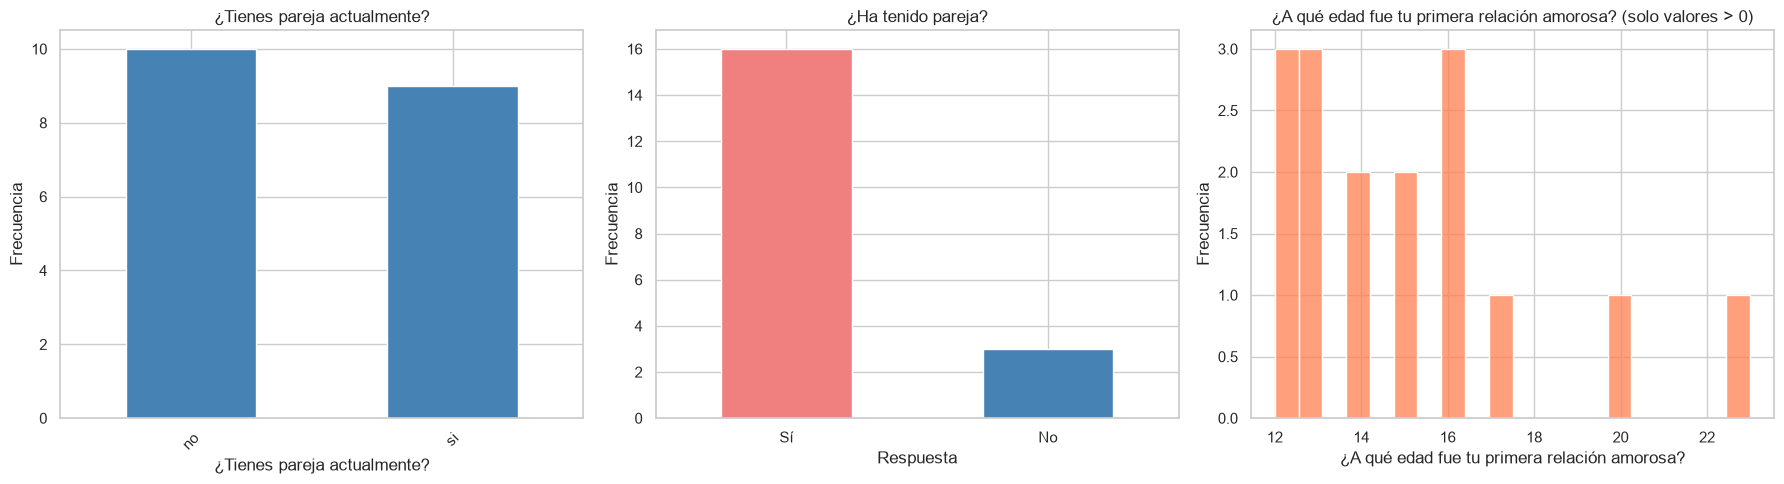

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Columna 1: Categórica (ha tenido pareja)
col_cat = df.columns[1]
counts = df[col_cat].value_counts()
counts.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title(f'{col_cat}')
axes[0].set_xlabel(col_cat)
axes[0].set_ylabel('Frecuencia')
axes[0].tick_params(axis='x', rotation=45)

# Columna 2: Numérica (primera pareja)
col_pareja = df.columns[2]

# Función para mapear: 0 -> "No", cualquier otra cosa -> "Sí"
def clasificar_pareja(valor):
    if pd.isna(valor):
        return "No especificado"
    return "Sí" if valor != 0 else "No"

# Aplicar el mapeo y contar frecuencias
serie_pareja = df[col_pareja].apply(clasificar_pareja)
counts_pareja = serie_pareja.value_counts()

# Graficar (usamos colores distintos para Sí/No)
colores = {'Sí': 'lightcoral', 'No': 'steelblue', 'No especificado': 'gray'}
bar_colors = [colores.get(x, 'gray') for x in counts_pareja.index]

counts_pareja.plot(kind='bar', ax=axes[1], color=bar_colors)
axes[1].set_title(f'¿Ha tenido pareja?')
axes[1].set_xlabel('Respuesta')
axes[1].set_ylabel('Frecuencia')
axes[1].tick_params(axis='x', rotation=0)

# Columna 2: Numérica (edad) - Solo valores > 0
df_edad_filtrada = df[df[col_pareja] > 0][col_pareja]
sns.histplot(df_edad_filtrada, bins=20, ax=axes[2], color='coral')
axes[2].set_title(f'{col_pareja} (solo valores > 0)')
axes[2].set_xlabel(col_pareja)
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

## Variables significativas

In [33]:
import yake
kw_extractor = yake.KeywordExtractor(lan="es", n=1, dedupLim=0.9, top=3, features=None)

def extraer_conceptos_yake(texto):
    """
    Extrae las palabras clave más representativas de un texto usando YAKE.
    """
    if pd.isna(texto) or str(texto).strip() == '':
        return pd.NA
    
    texto = str(texto).strip()
    
    # YAKE devuelve una lista de tuplas: [('palabra', puntaje), ('palabra2', puntaje2)]
    keywords = kw_extractor.extract_keywords(texto)
    
    if keywords:
        # Nos quedamos solo con las palabras (el primer elemento de cada tupla)
        # y las convertimos a minúsculas para unificar
        palabras_limpias = [kw[0].lower().strip() for kw in keywords]
        return ", ".join(palabras_limpias)
    else:
        return pd.NA

In [34]:
indices_listas = [4,5,6,7,8,9,11,12]
cols_listas = [df.columns[i] for i in indices_listas if i < len(df.columns)]

for col in cols_listas:
    nombre_nueva_col = f"{col}_conceptos"
    df[nombre_nueva_col] = df[col].apply(extraer_conceptos_yake)

print("✅ ¡Extracción completada sin errores de memoria!")

✅ ¡Extracción completada sin errores de memoria!


In [37]:
# Tomamos las primeras 2 columnas de listas como ejemplo para mostrar
cols_a_mostrar = cols_listas[4:6] 
cols_nuevas = [f"{c}_conceptos" for c in cols_a_mostrar]

# Mostramos solo estas 4 columnas (2 originales + 2 nuevas) de las primeras 10 filas
print("👀 Comparativa: Respuesta Original vs. Conceptos Extraídos")
display(df[cols_a_mostrar + cols_nuevas].head(10))

👀 Comparativa: Respuesta Original vs. Conceptos Extraídos


,"¿Cuáles son tus ""no negociables"" en una relación?",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?,"¿Cuáles son tus ""no negociables"" en una relación?_conceptos",¿Cuáles son las red flags (señales de alerta) que consideras dentro de una relación?_conceptos
1,"infidelidad, mentiras, enganos, tratar de cont...",frases para controlar o atacar emocionalmente ...,"infidelidad, mentiras, enganos","frases, controlar, atacar"
2,"infidelidad, falta de respeto",que me hable mucho de sus relaciones anteriore...,"infidelidad, falta, respeto","anteriores, toxico, hable"
3,-infidelidad -manipulacion -falta de empatia,"el que violente fisica, emocionalmente de mi a...","infidelidad, manipulacion, falta","fisica, emocionalmente, aislamiento"
4,que sea mentiroso que sea indeciso,controlador que sea grosero,"indeciso, mentiroso","controlador, grosero"
5,"infidelidad, no tener tiempo de calidad","revisar el telefono, que le “caigan mal” mis a...","infidelidad, calidad, tiempo","explicaciones, quiera, revisar"
6,*privacidad *espacio,"preguntas sobre donde estas, con quien o creer...","privacidad, espacio","preguntas, relacion, creer"
7,que no tenga ninguna adiccion a las sustancias...,cualquier tipo de violencia,"alcoholicas, adiccion, sustancias","violencia, tipo"
8,"falta de respeto, la infidelidad","mentiras constantes, control, posesividad, man...","falta, respeto, infidelidad","control, posesividad, mentiras"
9,"que no me tenga la confianza, que no me deje a...","revise tu celular, siga hablando con sus ex pa...","confianza, ayudar, deje","revise, celular, siga"
10,"falta de respeto, la falta de lealtad, confianza",tener controlada la situacion,"confianza, falta, respeto","situacion, controlada"


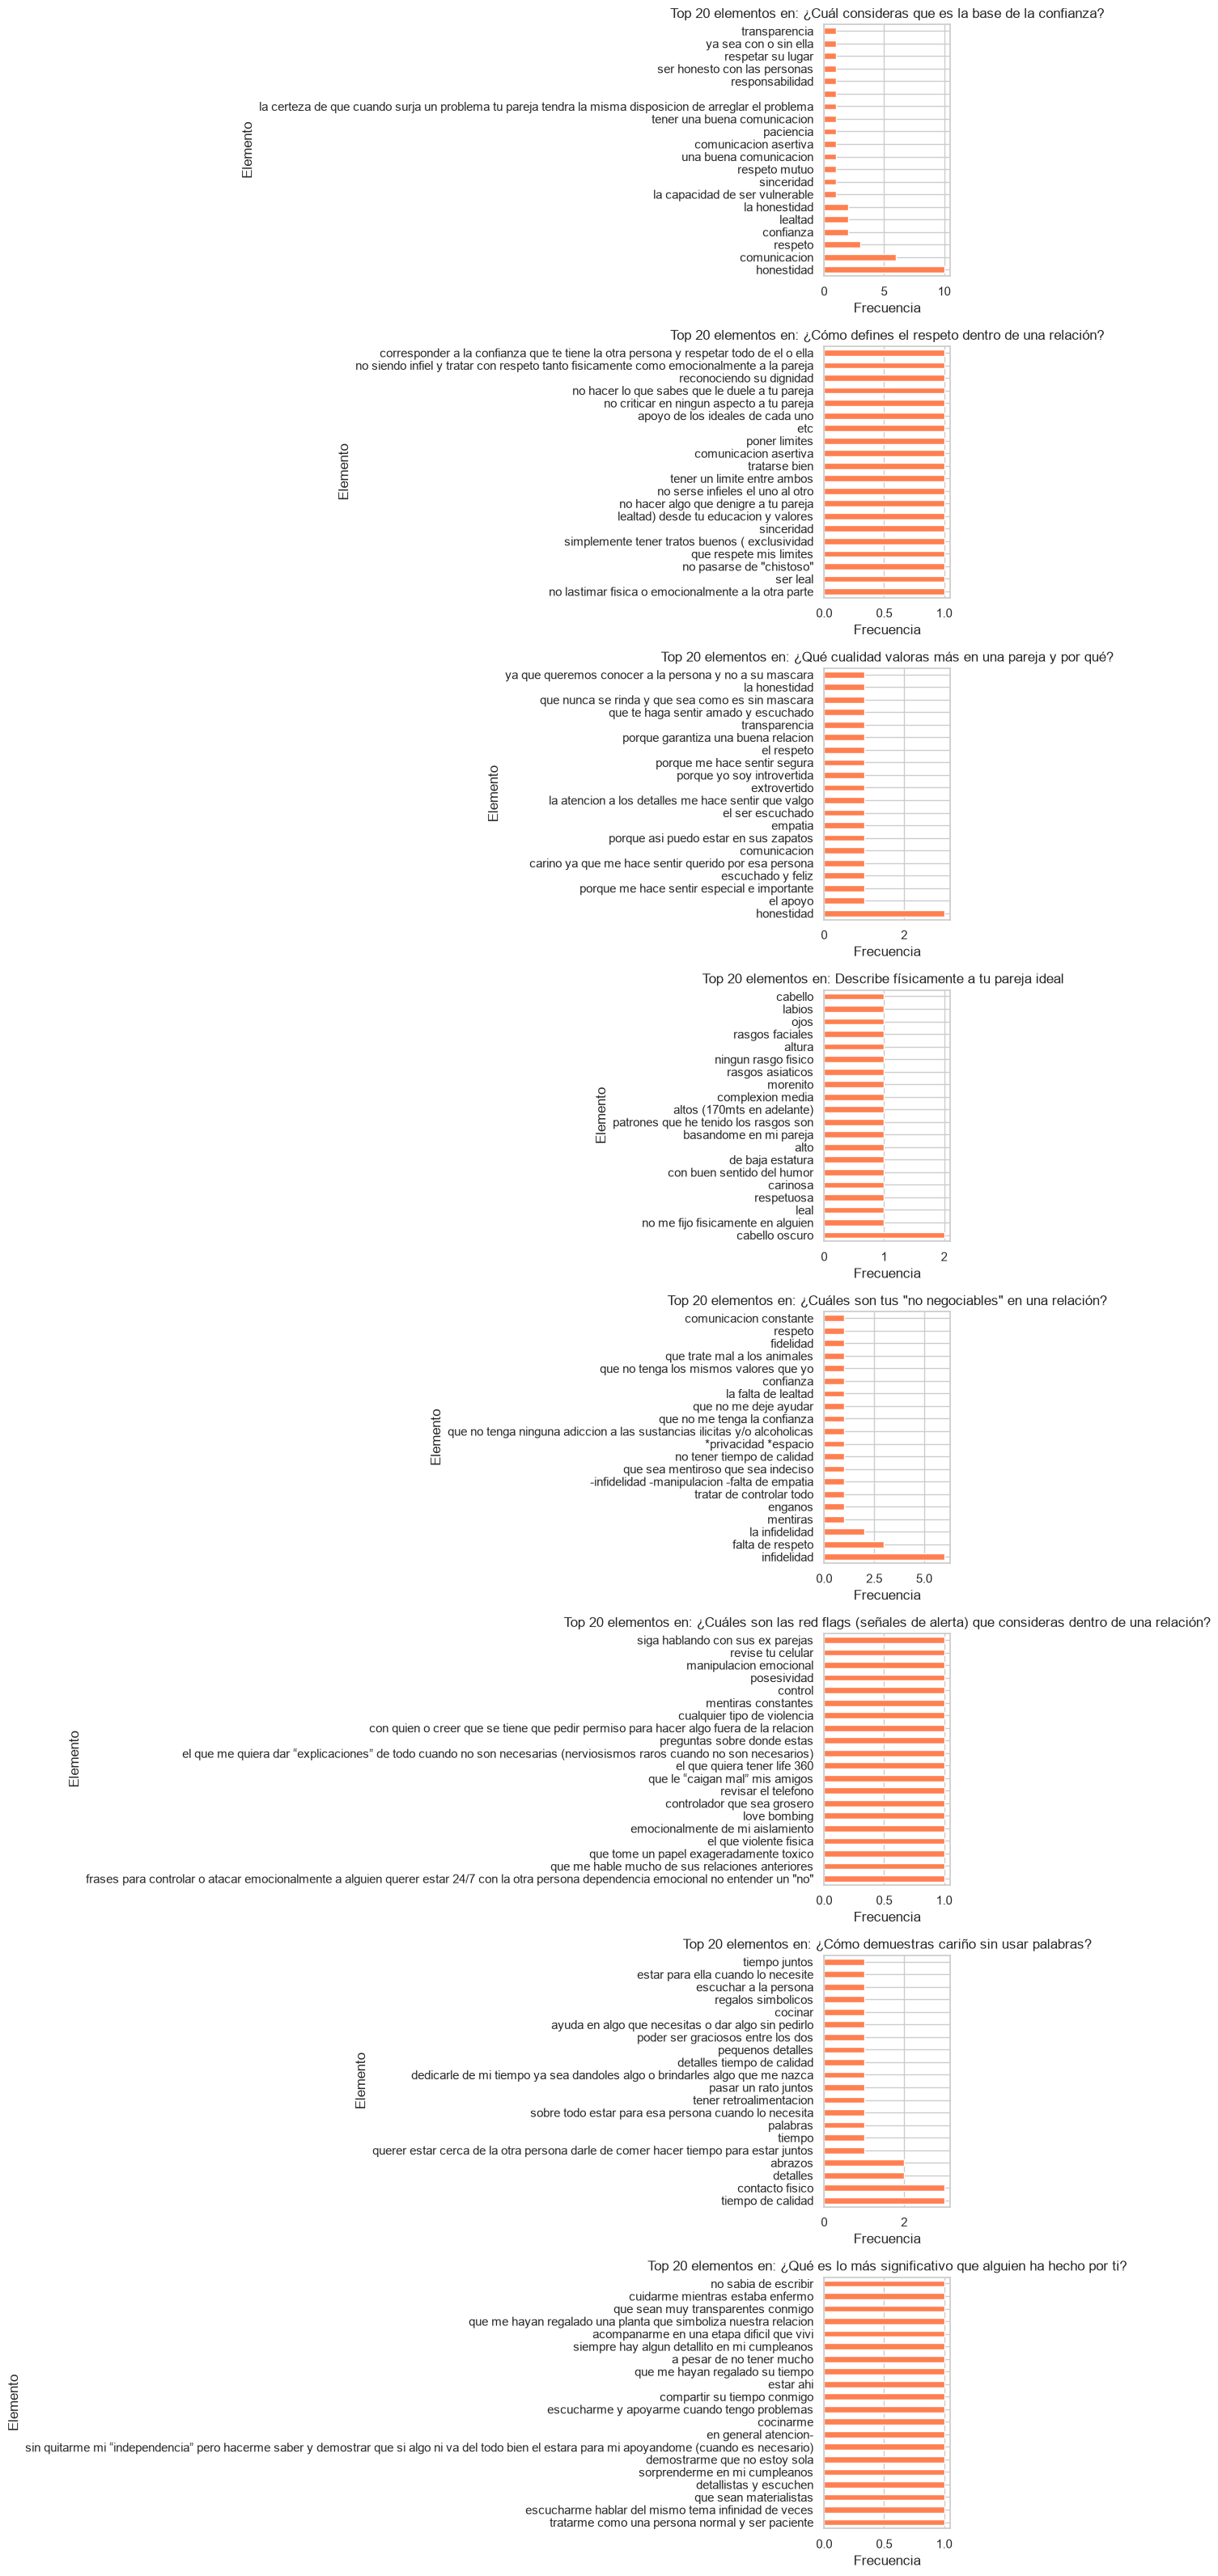

In [35]:
fig, axes = plt.subplots(len(cols_listas), 1, figsize=(12, 4 * len(cols_listas)))

if len(cols_listas) == 1:
    axes = [axes]

for i, col in enumerate(cols_listas):
    ax = axes[i]
    
    # Separar por comas, explotar y contar
    palabras = df[col].dropna().str.split(', ').explode()
    conteo = palabras.value_counts().head(20)  # Top 20
    
    if len(conteo) > 0:
        conteo.plot(kind='barh', ax=ax, color='coral')
        ax.set_title(f'Top 20 elementos en: {col}')
        ax.set_xlabel('Frecuencia')
        ax.set_ylabel('Elemento')
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
        ax.set_title(f'{col}')

plt.tight_layout()
plt.show()

## 5. Exportar datos limpios

In [36]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_CSV, index=False)
print(f"✓ Datos limpios guardados en: {PROCESSED_CSV}")
print(f"  Filas: {len(df)}")
print(f"  Columnas: {len(df.columns)}")

✓ Datos limpios guardados en: C:\Users\Angel\Desktop\Sistemas Inteligentes\LimpiezaData\data\processed\datos_limpios.csv
  Filas: 19
  Columnas: 24
